# Check Eye-Tracking Data

This Notebook is to test the eyetracking data and if the labels for the fixations were extracted correctly.

In [4]:
import os
import sys
import warnings
import pandas as pd

sys.path.append("../..")

from data.data_configs import ALL_SUBJECTS
from data.data_testing.check_et_labels_utils import plot_stimulus_for_subject, list_available_stimuli, load_events

warnings.filterwarnings("ignore") 

### Plot Stimuli for subjects to see if the ET data looks correct
- Are the coordinates correct?
- Are the boxes around the planes?
- Are the fixations labels correctly?
- Are there missing fixations?
- etc.

Subject P01
Selected random stimulus for P01: 11224
Fixations: total=8, on-target=3, off-target=5


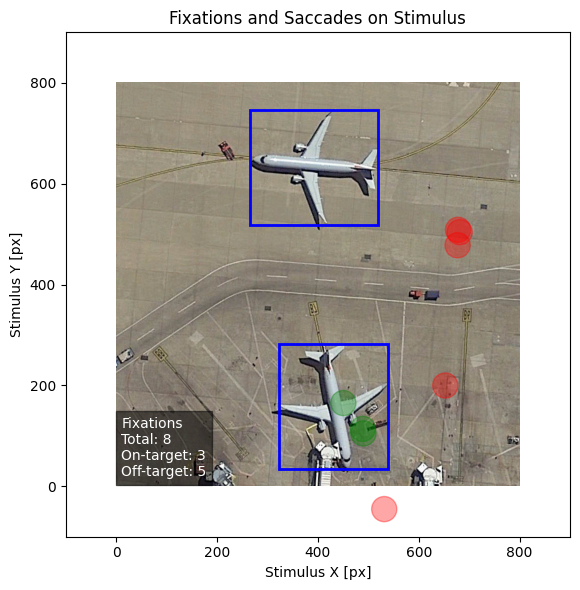

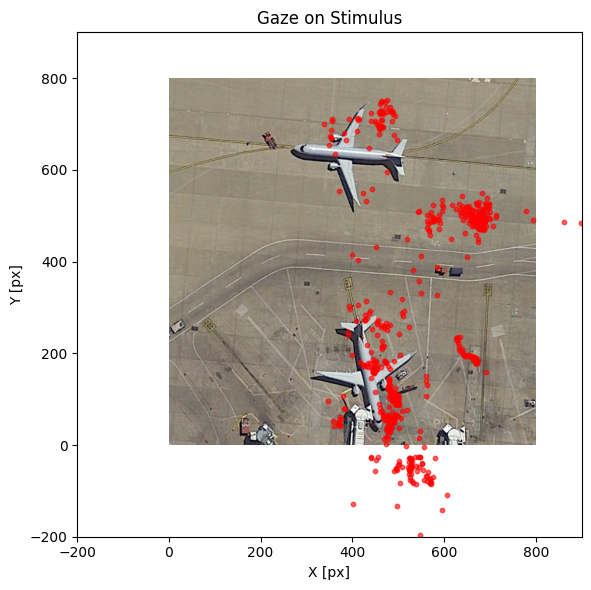

In [5]:
for subj in ALL_SUBJECTS:
    print(f"Subject {subj}")
    plot_stimulus_for_subject(subj, also_gaze=True, stimulus=None)
    break

### Check for zero fixations 

Above some images didnt show any fixations, so we check how many trials without fixations stimuli exist per subject. A look at the data tells that some subjects have messed up data. That is, for the Exe tracking many values are missing for some stimuli, therefore we can not use it for further analysis. Subjects with a zero fixation rate above 5% will be removed from the final set of participants.

In [6]:
summary_rows = []
for subj in ALL_SUBJECTS:
    events = load_events(subj)
    available = set(list_available_stimuli(subj))
    event_stims = set(events['stimulus'].dropna().unique().tolist())
    candidate_stims = sorted(event_stims & available)

    zero_fix_stims = []
    for stim in candidate_stims:
        evs = events[events['stimulus'] == stim]
        fix = evs[evs['event_type'] == 'Fixation']
        if len(fix) == 0:
            zero_fix_stims.append(stim)

    total = len(candidate_stims)
    zero_count = len(zero_fix_stims)
    pct_zero = (zero_count / total * 100.0) if total > 0 else 0.0

    summary_rows.append({
        'subject': subj,
        'stimuli': total,
        'zero_fixations': zero_count,
        'pct_zero_fix': round(pct_zero, 1)
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,subject,stimuli,zero_fixations,pct_zero_fix
0,P01,501,0,0.0
1,P02,501,1,0.2
2,P03,501,315,62.9
3,P04,501,287,57.3
4,P05,501,17,3.4
5,P06,501,0,0.0
6,P07,501,0,0.0
7,P08,501,282,56.3
8,P09,501,0,0.0
9,P10,501,0,0.0


In [8]:
# Subjects with >5% zero-fixations
summary_df.loc[summary_df['pct_zero_fix'] > 5, 'subject'].tolist()

['P03', 'P04', 'P08', 'P13', 'P18', 'P22']